In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!unzip "/content/drive/MyDrive/PR/EuroSAT_RGB.zip" -d "/content/EN3150_Assignment_03/data/"

Streaming output truncated to the last 5000 lines.
  inflating: /content/EN3150_Assignment_03/data/EuroSAT_RGB/Residential/Residential_489.jpg  
  inflating: /content/EN3150_Assignment_03/data/EuroSAT_RGB/Residential/Residential_1573.jpg  
  inflating: /content/EN3150_Assignment_03/data/EuroSAT_RGB/Residential/Residential_270.jpg  
  inflating: /content/EN3150_Assignment_03/data/EuroSAT_RGB/Residential/Residential_516.jpg  
  inflating: /content/EN3150_Assignment_03/data/EuroSAT_RGB/Residential/Residential_2683.jpg  
  inflating: /content/EN3150_Assignment_03/data/EuroSAT_RGB/Residential/Residential_502.jpg  
  inflating: /content/EN3150_Assignment_03/data/EuroSAT_RGB/Residential/Residential_2697.jpg  
  inflating: /content/EN3150_Assignment_03/data/EuroSAT_RGB/Residential/Residential_264.jpg  
  inflating: /content/EN3150_Assignment_03/data/EuroSAT_RGB/Residential/Residential_2867.jpg  
  inflating: /content/EN3150_Assignment_03/data/EuroSAT_RGB/Residential/Residential_2873.jpg  
  in

In [4]:
%cd /content/EN3150_Assignment_03/notebooks

/content/EN3150_Assignment_03/notebooks


In [5]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

In [6]:
!pip install -q torchinfo

import torch
import pandas as pd
import torch.nn as nn
import matplotlib.pyplot as plt
from torchinfo import summary
from models.standard_cnn import StandardCNN
from models.lightweight_cnn import LightweightCNN
from data_prep import create_dataloaders
from utils import (
    count_parameters,
    train_model,
    evaluate_model,
    plot_training_history,
    plot_confusion_matrix,
    model_size_kb,
)

In [7]:
DATASET_DIR = '/content/EN3150_Assignment_03/data/EuroSAT_RGB'

BATCH_SIZE = 64
NUM_EPOCHS = 20
LEARNING_RATE = 0.001

SEED = 26
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


In [8]:
train_loader, val_loader, test_loader, class_names, mean, std = create_dataloaders(
    dataset_dir=DATASET_DIR,
    batch_size=BATCH_SIZE,
    seed=SEED,
    image_size=64,
)

print("Training mean:", mean.tolist())
print("Training std: ", std.tolist())
print("Training:", len(train_loader.dataset))
print("Validation:", len(val_loader.dataset))
print("Testing:", len(test_loader.dataset))

Training mean: [0.34376397728919983, 0.3799758851528168, 0.40765735507011414]
Training std:  [0.2026132196187973, 0.13695679605007172, 0.11558672785758972]
Training: 18900
Validation: 4050
Testing: 4050


In [9]:
model_a = StandardCNN(num_classes=len(class_names)).to(DEVICE)

summary(model_a, input_size=(1, 3, 64, 64))
print(f"Model A trainable parameters: {count_parameters(model_a):,}")
print(f"Model A size: {model_size_kb(model_a):.2f} KB")

Model A trainable parameters: 914,122
Model A size: 3570.79 KB


In [10]:
model_b = LightweightCNN(num_classes=len(class_names)).to(DEVICE)

summary(model_b, input_size=(1, 3, 64, 64))
print(f"Model B trainable parameters: {count_parameters(model_b):,}")
print(f"Model B size: {model_size_kb(model_b):.2f} KB")

Model B trainable parameters: 59,301
Model B size: 231.64 KB


In [11]:
NUM_EPOCHS = 20

# Create one initial set of weights for a fair comparison
torch.manual_seed(SEED)
initial_model = StandardCNN(num_classes=10)
initial_weights = initial_model.state_dict()

criterion = nn.CrossEntropyLoss()

optimizer_configs = {
    "Adam": {"name": "Adam", "lr": 0.001},
    "SGD": {"name": "SGD", "lr": 0.01},
    "SGD + Momentum": {
        "name": "SGD_Momentum",
        "lr": 0.01,
        "momentum": 0.9,
    },
}

histories = {}
comparison = []

for experiment, config in optimizer_configs.items():
    # Reset the model to identical initial weights
    model = StandardCNN(num_classes=10).to(DEVICE)
    model.load_state_dict(initial_weights)

    if config["name"] == "Adam":
        optimizer = torch.optim.Adam(
            model.parameters(), lr=config["lr"]
        )
    elif config["name"] == "SGD":
        optimizer = torch.optim.SGD(
            model.parameters(), lr=config["lr"]
        )
    else:
        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=config["lr"],
            momentum=config["momentum"],
        )

    # Reset RNG for comparable shuffled batches
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    print(f"\nExperiment: {experiment}")

    history = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=DEVICE,
        num_epochs=NUM_EPOCHS,
    )

    histories[experiment] = history

    comparison.append({
        "Optimizer": experiment,
        "Learning Rate": config["lr"],
        "Best Validation Accuracy (%)":
            100 * max(history["val_accuracy"]),
        "Final Validation Loss": history["val_loss"][-1],
        "Avg. Epoch Time (s)":
            sum(history["epoch_time"]) / len(history["epoch_time"]),
    })


Experiment: Adam
Epoch [01/20] Train Loss: 1.0309 | Train Acc: 0.6110 | Val Loss: 0.6815 | Val Acc: 0.7593 | Time: 7.68s
Epoch [02/20] Train Loss: 0.6231 | Train Acc: 0.7762 | Val Loss: 0.4779 | Val Acc: 0.8299 | Time: 7.10s
Epoch [03/20] Train Loss: 0.4873 | Train Acc: 0.8285 | Val Loss: 0.4585 | Val Acc: 0.8358 | Time: 7.28s
Epoch [04/20] Train Loss: 0.3910 | Train Acc: 0.8624 | Val Loss: 0.3606 | Val Acc: 0.8785 | Time: 7.28s
Epoch [05/20] Train Loss: 0.3121 | Train Acc: 0.8897 | Val Loss: 0.3086 | Val Acc: 0.8931 | Time: 7.03s
Epoch [06/20] Train Loss: 0.2463 | Train Acc: 0.9152 | Val Loss: 0.2918 | Val Acc: 0.8978 | Time: 7.30s
Epoch [07/20] Train Loss: 0.2173 | Train Acc: 0.9240 | Val Loss: 0.3146 | Val Acc: 0.8931 | Time: 7.18s
Epoch [08/20] Train Loss: 0.1825 | Train Acc: 0.9378 | Val Loss: 0.2657 | Val Acc: 0.9094 | Time: 7.34s
Epoch [09/20] Train Loss: 0.1502 | Train Acc: 0.9469 | Val Loss: 0.2435 | Val Acc: 0.9198 | Time: 7.25s
Epoch [10/20] Train Loss: 0.1404 | Train Acc: 

,Optimizer,Learning Rate,Best Validation Accuracy (%),Final Validation Loss,Avg. Epoch Time (s)
0,Adam,0.001,93.0123,0.3032,7.1995
2,SGD + Momentum,0.010,92.9383,0.4157,7.1560
1,SGD,0.010,79.2840,0.5737,7.1126


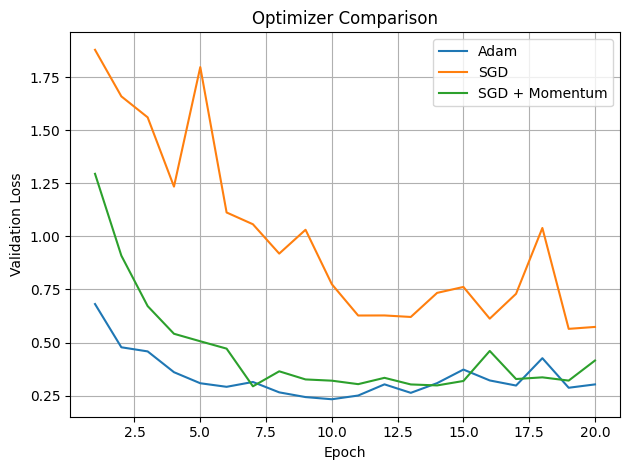

In [12]:
comparison_df = pd.DataFrame(comparison)
comparison_df = comparison_df.sort_values(
    "Best Validation Accuracy (%)", ascending=False
)

display(comparison_df.round(4))

for name, history in histories.items():
    plt.plot(
        range(1, NUM_EPOCHS + 1),
        history["val_loss"],
        label=name,
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Optimizer Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
model_a = StandardCNN(num_classes=len(class_names)).to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model_a.parameters(),
    lr=LEARNING_RATE
)

history_a = train_model(
    model=model_a,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=DEVICE,
    num_epochs=NUM_EPOCHS,
)

save_path_a = '/content/drive/MyDrive/PR/model_a_checkpoint.pth'

torch.save({
    'model_state_dict': model_a.state_dict(),
    'optimizer_state_dict': optimizer.state_dict()
}, save_path_a)

print(f"Model A checkpoint safely saved to Google Drive.")

Epoch [01/20] Train Loss: 1.0725 | Train Acc: 0.5943 | Val Loss: 0.6657 | Val Acc: 0.7625 | Time: 7.11s
Epoch [02/20] Train Loss: 0.6343 | Train Acc: 0.7735 | Val Loss: 0.5444 | Val Acc: 0.8077 | Time: 7.16s
Epoch [03/20] Train Loss: 0.4944 | Train Acc: 0.8264 | Val Loss: 0.4277 | Val Acc: 0.8447 | Time: 7.09s
Epoch [04/20] Train Loss: 0.4151 | Train Acc: 0.8529 | Val Loss: 0.4445 | Val Acc: 0.8422 | Time: 7.15s
Epoch [05/20] Train Loss: 0.3271 | Train Acc: 0.8844 | Val Loss: 0.3057 | Val Acc: 0.8933 | Time: 7.23s
Epoch [06/20] Train Loss: 0.2701 | Train Acc: 0.9075 | Val Loss: 0.2893 | Val Acc: 0.9064 | Time: 7.11s
Epoch [07/20] Train Loss: 0.2314 | Train Acc: 0.9184 | Val Loss: 0.2675 | Val Acc: 0.9091 | Time: 7.13s
Epoch [08/20] Train Loss: 0.1887 | Train Acc: 0.9329 | Val Loss: 0.2922 | Val Acc: 0.8975 | Time: 7.22s
Epoch [09/20] Train Loss: 0.1616 | Train Acc: 0.9418 | Val Loss: 0.2902 | Val Acc: 0.9059 | Time: 7.18s
Epoch [10/20] Train Loss: 0.1362 | Train Acc: 0.9538 | Val Loss:

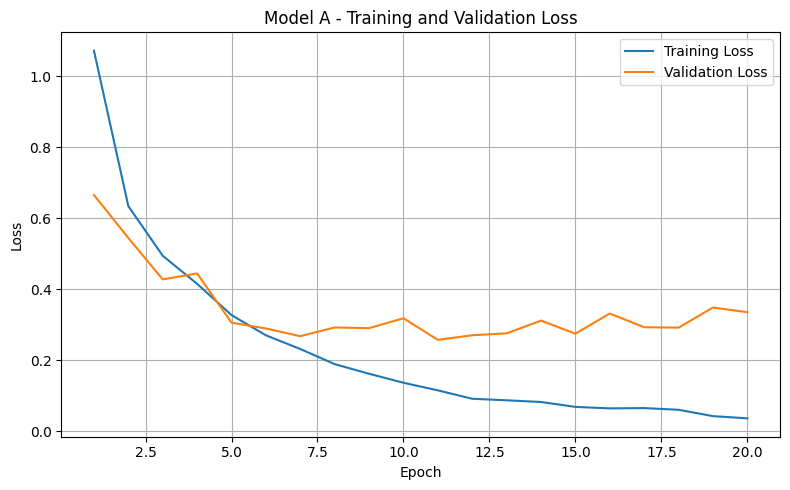

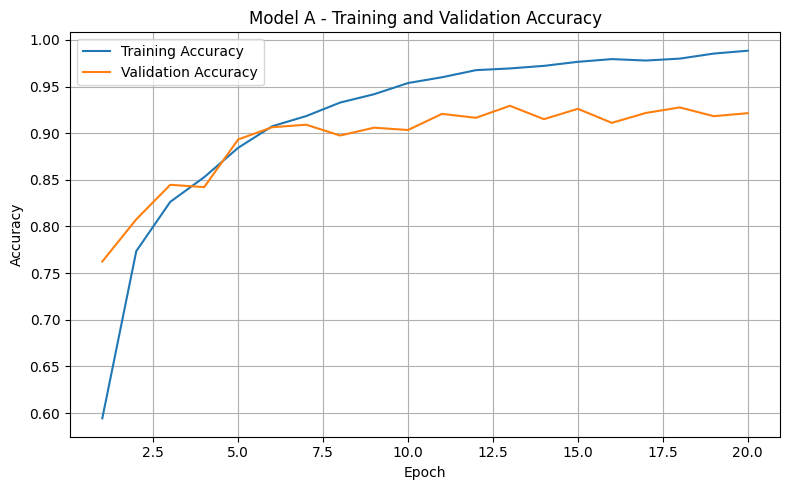

Test Accuracy : 0.9230
Test Precision: 0.9220
Test Recall   : 0.9202


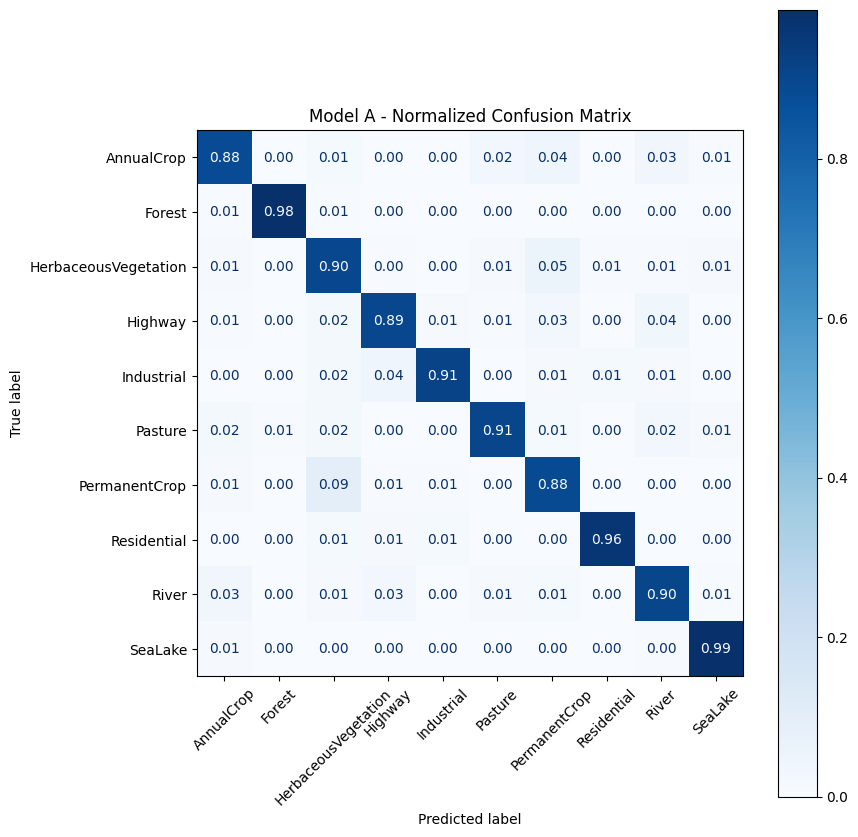

In [14]:
plot_training_history(history_a, model_name="Model A")

results_a = evaluate_model(model_a, test_loader, device=DEVICE)
print(f"Test Accuracy : {results_a['accuracy']:.4f}")
print(f"Test Precision: {results_a['precision']:.4f}")
print(f"Test Recall   : {results_a['recall']:.4f}")

plot_confusion_matrix(
    results_a["confusion_matrix"],
    class_names,
    model_name="Model A"
)

In [15]:
model_b = LightweightCNN(num_classes=len(class_names)).to(DEVICE)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model_b.parameters(),
    lr=LEARNING_RATE
)

history_b = train_model(
    model=model_b,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=DEVICE,
    num_epochs=NUM_EPOCHS,
)

save_path_b = '/content/drive/MyDrive/PR/model_b_checkpoint.pth'

torch.save({
    'model_state_dict': model_b.state_dict(),
    'optimizer_state_dict': optimizer.state_dict()
}, save_path_b)

print(f"Model B checkpoint safely saved to Google Drive.")

Epoch [01/20] Train Loss: 1.6075 | Train Acc: 0.3580 | Val Loss: 1.2797 | Val Acc: 0.4807 | Time: 7.26s
Epoch [02/20] Train Loss: 1.1220 | Train Acc: 0.5767 | Val Loss: 0.9770 | Val Acc: 0.6588 | Time: 7.10s
Epoch [03/20] Train Loss: 0.8848 | Train Acc: 0.6819 | Val Loss: 0.8762 | Val Acc: 0.6938 | Time: 7.09s
Epoch [04/20] Train Loss: 0.7794 | Train Acc: 0.7225 | Val Loss: 0.7927 | Val Acc: 0.7237 | Time: 7.24s
Epoch [05/20] Train Loss: 0.7098 | Train Acc: 0.7462 | Val Loss: 0.6827 | Val Acc: 0.7605 | Time: 7.29s
Epoch [06/20] Train Loss: 0.6482 | Train Acc: 0.7702 | Val Loss: 0.6886 | Val Acc: 0.7543 | Time: 7.01s
Epoch [07/20] Train Loss: 0.6190 | Train Acc: 0.7776 | Val Loss: 0.6550 | Val Acc: 0.7738 | Time: 7.06s
Epoch [08/20] Train Loss: 0.5836 | Train Acc: 0.7906 | Val Loss: 0.5954 | Val Acc: 0.7899 | Time: 7.31s
Epoch [09/20] Train Loss: 0.5572 | Train Acc: 0.8018 | Val Loss: 0.6428 | Val Acc: 0.7679 | Time: 7.23s
Epoch [10/20] Train Loss: 0.5450 | Train Acc: 0.8053 | Val Loss:

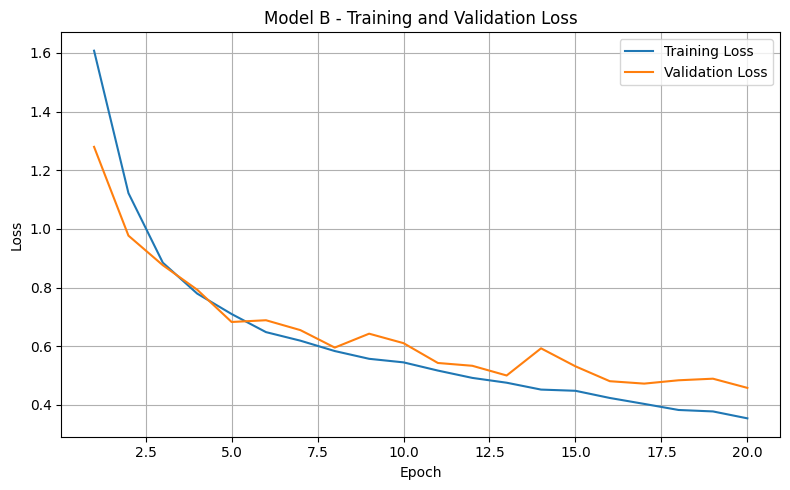

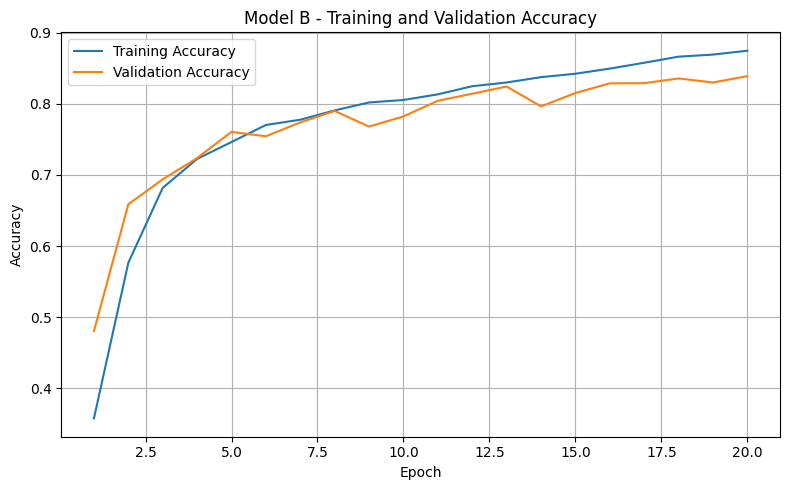

Test Accuracy : 0.8486
Test Precision: 0.8452
Test Recall   : 0.8423


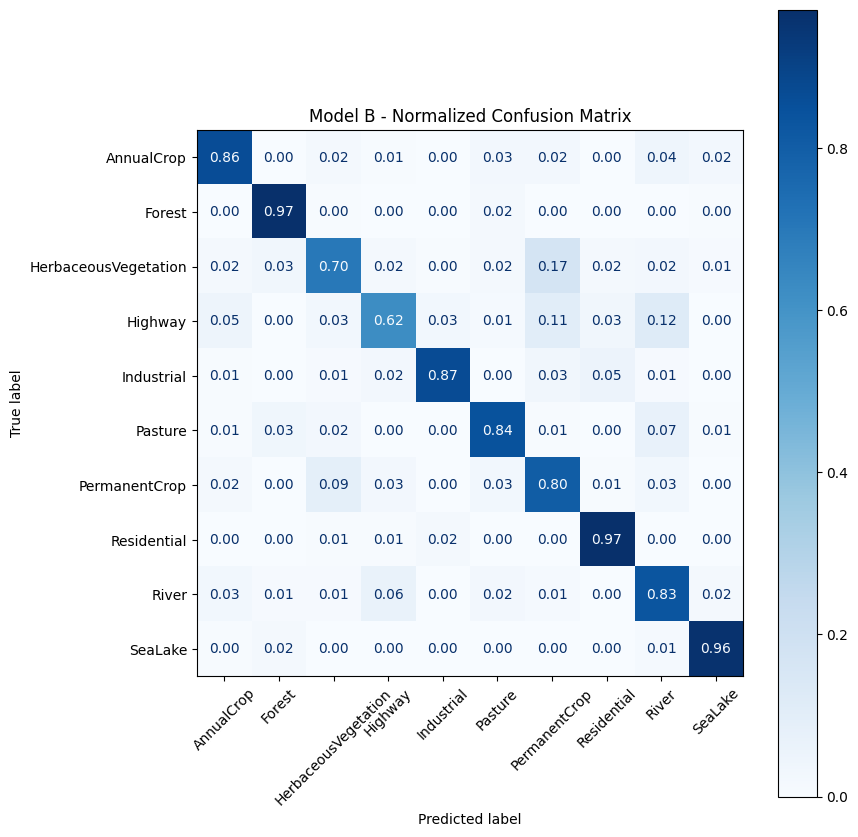

In [16]:
plot_training_history(history_b, model_name="Model B")

results_b = evaluate_model(model_b, test_loader, device=DEVICE)
print(f"Test Accuracy : {results_b['accuracy']:.4f}")
print(f"Test Precision: {results_b['precision']:.4f}")
print(f"Test Recall   : {results_b['recall']:.4f}")

plot_confusion_matrix(
    results_b["confusion_matrix"],
    class_names,
    model_name="Model B"
)

# Section 2: Compare with Lightweight State-of-the-Art Networks
In this section, we fine-tune and evaluate two pre-trained lightweight architectures on the EuroSAT dataset:
1. **SqueezeNet 1.1** (utilizing Fire Modules)
2. **MobileNetV2** (utilizing Inverted Residuals with Linear Bottlenecks)


In [ ]:
import torchvision.models as models

# ------------------------------------------------------------
# 1. SqueezeNet 1.1 Adaptation & Training
# ------------------------------------------------------------
model_squeezenet = models.squeezenet1_1(weights=models.SqueezeNet1_1_Weights.DEFAULT)

# Adapt classification head for 10 classes
model_squeezenet.classifier[1] = nn.Conv2d(512, len(class_names), kernel_size=1)
model_squeezenet.num_classes = len(class_names)
model_squeezenet = model_squeezenet.to(DEVICE)

print(f"SqueezeNet 1.1 trainable parameters: {count_parameters(model_squeezenet):,}")
print(f"SqueezeNet 1.1 size: {model_size_kb(model_squeezenet):.2f} KB ({model_size_kb(model_squeezenet)/1024:.2f} MB)")

# Fine-tuning with lower learning rate for transfer learning
SOTA_LR = 0.0001
criterion = nn.CrossEntropyLoss()

optimizer_sq = torch.optim.Adam(model_squeezenet.parameters(), lr=SOTA_LR)

history_sq = train_model(
    model=model_squeezenet,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_sq,
    device=DEVICE,
    num_epochs=NUM_EPOCHS,
)

save_path_sq = "/content/drive/MyDrive/PR/squeezenet_checkpoint.pth"
torch.save({
    "model_state_dict": model_squeezenet.state_dict(),
    "optimizer_state_dict": optimizer_sq.state_dict()
}, save_path_sq)
print("SqueezeNet 1.1 checkpoint safely saved to Google Drive.")


In [ ]:
plot_training_history(history_sq, model_name="SqueezeNet 1.1")

results_sq = evaluate_model(model_squeezenet, test_loader, device=DEVICE)
print(f"Test Accuracy : {results_sq['accuracy']:.4f}")
print(f"Test Precision: {results_sq['precision']:.4f}")
print(f"Test Recall   : {results_sq['recall']:.4f}")

plot_confusion_matrix(
    results_sq["confusion_matrix"],
    class_names,
    model_name="SqueezeNet 1.1"
)


In [ ]:
# ------------------------------------------------------------
# 2. MobileNetV2 Adaptation & Training
# ------------------------------------------------------------
model_mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

# Adapt classification head for 10 classes
model_mobilenet.classifier[1] = nn.Linear(model_mobilenet.last_channel, len(class_names))
model_mobilenet = model_mobilenet.to(DEVICE)

print(f"MobileNetV2 trainable parameters: {count_parameters(model_mobilenet):,}")
print(f"MobileNetV2 size: {model_size_kb(model_mobilenet):.2f} KB ({model_size_kb(model_mobilenet)/1024:.2f} MB)")

optimizer_mb = torch.optim.Adam(model_mobilenet.parameters(), lr=SOTA_LR)

history_mb = train_model(
    model=model_mobilenet,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_mb,
    device=DEVICE,
    num_epochs=NUM_EPOCHS,
)

save_path_mb = "/content/drive/MyDrive/PR/mobilenetv2_checkpoint.pth"
torch.save({
    "model_state_dict": model_mobilenet.state_dict(),
    "optimizer_state_dict": optimizer_mb.state_dict()
}, save_path_mb)
print("MobileNetV2 checkpoint safely saved to Google Drive.")


In [ ]:
plot_training_history(history_mb, model_name="MobileNetV2")

results_mb = evaluate_model(model_mobilenet, test_loader, device=DEVICE)
print(f"Test Accuracy : {results_mb['accuracy']:.4f}")
print(f"Test Precision: {results_mb['precision']:.4f}")
print(f"Test Recall   : {results_mb['recall']:.4f}")

plot_confusion_matrix(
    results_mb["confusion_matrix"],
    class_names,
    model_name="MobileNetV2"
)


In [ ]:
# ------------------------------------------------------------
# 3. Master Comparison across all 4 models
# ------------------------------------------------------------
master_comparison = pd.DataFrame([
    {
        "Model": "Model B (Lightweight CNN)",
        "Type": "Custom (Depthwise Separable)",
        "Pretrained": False,
        "Parameters": count_parameters(model_b),
        "Size (KB)": model_size_kb(model_b),
        "Size (MB)": model_size_kb(model_b) / 1024,
        "Test Accuracy (%)": results_b["accuracy"] * 100,
        "Test Precision (%)": results_b["precision"] * 100,
        "Test Recall (%)": results_b["recall"] * 100,
    },
    {
        "Model": "Model A (Standard CNN)",
        "Type": "Custom (Standard 2D Conv)",
        "Pretrained": False,
        "Parameters": count_parameters(model_a),
        "Size (KB)": model_size_kb(model_a),
        "Size (MB)": model_size_kb(model_a) / 1024,
        "Test Accuracy (%)": results_a["accuracy"] * 100,
        "Test Precision (%)": results_a["precision"] * 100,
        "Test Recall (%)": results_a["recall"] * 100,
    },
    {
        "Model": "SqueezeNet 1.1",
        "Type": "SOTA (Fire Modules)",
        "Pretrained": True,
        "Parameters": count_parameters(model_squeezenet),
        "Size (KB)": model_size_kb(model_squeezenet),
        "Size (MB)": model_size_kb(model_squeezenet) / 1024,
        "Test Accuracy (%)": results_sq["accuracy"] * 100,
        "Test Precision (%)": results_sq["precision"] * 100,
        "Test Recall (%)": results_sq["recall"] * 100,
    },
    {
        "Model": "MobileNetV2",
        "Type": "SOTA (Inverted Residuals)",
        "Pretrained": True,
        "Parameters": count_parameters(model_mobilenet),
        "Size (KB)": model_size_kb(model_mobilenet),
        "Size (MB)": model_size_kb(model_mobilenet) / 1024,
        "Test Accuracy (%)": results_mb["accuracy"] * 100,
        "Test Precision (%)": results_mb["precision"] * 100,
        "Test Recall (%)": results_mb["recall"] * 100,
    },
])

display(master_comparison.round(2))
